In [ ]:
!pip install -U transformers
!pip install -q bitsandbytes accelerate transformers

In [ ]:
import torch

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

True
Tesla T4


In [ ]:
import torch
import torch_xla

device = torch_xla.device()

In [ ]:
import librosa
import torch
import pandas as pd
import numpy as np
from pathlib import Path

import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, f1_score,confusion_matrix,accuracy_score,precision_score,recall_score
from sklearn.model_selection import train_test_split

In [ ]:
from transformers import AutoProcessor, Qwen2AudioForConditionalGeneration


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GiB"
    )

Device: cuda
GPU: Tesla T4
VRAM: 14.56 GiB


## Local Inference on GPU
Model page: https://huggingface.co/Qwen/Qwen2.5-Omni-7B

⚠️ If the generated code snippets do not work, please open an issue on either the [model repo](https://huggingface.co/Qwen/Qwen2.5-Omni-7B)
			and/or on [huggingface.js](https://github.com/huggingface/huggingface.js/blob/main/packages/tasks/src/model-libraries-snippets.ts) 🙏

In [ ]:
import torch
from transformers import (
    AutoProcessor,
    Qwen2AudioForConditionalGeneration,
    BitsAndBytesConfig
)
MODEL_ID = "Qwen/Qwen2-Audio-7B-Instruct"

processor = AutoProcessor.from_pretrained(MODEL_ID)

model = Qwen2AudioForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    low_cpu_mem_usage=True

)

model.eval()

Loading weights:   0%|          | 0/876 [00:00<?, ?it/s]

In [ ]:
import gc
gc.collect()
torch.cuda.empty_cache()

NameError: name 'torch' is not defined

In [ ]:
print(model.device)

cpu


In [ ]:
emotions = [
    "anger",
    "disgust",
    "fear",
    "happiness",
    "sadness"
]

In [ ]:
def predict_emotion(wav_path, emotions):
    # Qwen processor tells us which sampling rate it expects
    target_sr = processor.feature_extractor.sampling_rate

    audio, sr = librosa.load(
        wav_path,
        sr=target_sr,
        mono=True
    )

    emotion_string = ", ".join(emotions)


  reasoning_prompt = f"""
    Given the Content: {content}
    Emotion: {emotion}

    Provide a detailed reasoning that explains how the emotion and its intensity
    relate to the spoken content and the audio's characteristics, such as tone,
    pitch, speaking style, clarity, and other acoustic properties.

    ## Here are some rules you should follow:
    - DO NOT use the word "{emotion}" in your reasoning.
    - DO NOT use open-ended questions or follow-up invitations in the reasoning.
    - DO NOT use "Well, you know" or "Well" in the reasoning.
    """
cot_prompt = f"""
    Provide a detailed reasoning that explains how the emotion and its intensity
    relate to the spoken content and the audio's characteristics, such as tone,
    pitch, speaking style, clarity, and other acoustic properties.

    ## Here are some rules you should follow:
    - DO NOT use the word "{emotion}" in your reasoning.
    - DO NOT use open-ended questions or follow-up invitations in the reasoning.
    - DO NOT use "Well, you know" or "Well" in the reasoning.


  Then choose exactly one emotion from:
  {emotion_string}

Return ONLY valid JSON in exactly this format:

{{
  "reasoning": "brief explanation of the acoustic cues",
  "emotion": "one label from the allowed list"
}}

Do not include markdown.
Do not include any text before or after the JSON.
"""
    conversation = [
        {
            "role": "user",
            "content": [
                {
                    "type": "audio",
                    "audio_url": str(wav_path)
                },
                {
                    "type": "text",
                    "text": cot_prompt

                }
            ]
        }
    ]

    text = processor.apply_chat_template(
        conversation,
        add_generation_prompt=True,
        tokenize=False
    )

    inputs = processor(
        text=text,
        audio=[audio],
        return_tensors="pt",
        padding=True
    ).to(model.device)
    inputs = {
    k: v.to(model.device) if torch.is_tensor(v) else v
    for k, v in inputs.items()
    }

    with torch.inference_mode():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=10,
            do_sample=False
        )

    # Remove input/prompt tokens
    generated_ids = generated_ids[:, inputs["input_ids"].size(1):]

    response = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )[0]

    return response.strip().lower()

In [ ]:
def parse_qwen_response(response, emotions):
    try:
        data = json.loads(response)

        reasoning = data.get("reasoning", "")
        emotion = data.get("emotion", "").lower().strip()

        if emotion not in emotions:
            emotion = "invalid"

        return reasoning, emotion

    except json.JSONDecodeError:
        return response, "invalid"

In [ ]:
import json
import librosa
import torch


def predict_emotion_cot_json(wav_path, processor, model, emotions):
    emotion_string = ", ".join(emotions)

    cot_prompt = f"""
    Provide a detailed reasoning that explains how the emotion and its intensity
    relate to the spoken content and the audio's characteristics, such as tone,
    pitch, speaking style, clarity, and other acoustic properties.

    ## Here are some rules you should follow:
    - Do not explicitly name an emotion in the reasoning.
    - DO NOT use open-ended questions or follow-up invitations in the reasoning.
    - DO NOT use "Well, you know" or "Well" in the reasoning.


      Then choose exactly one emotion from:
      {emotion_string}

    Return ONLY valid JSON in exactly this format:

    {{
      "reasoning": "brief explanation of the acoustic cues",
      "emotion": "one label from the allowed list"
    }}

    Do not include markdown.
    Do not include any text before or after the JSON.
    """

    conversation = [
        {
            "role": "user",
            "content": [
                {
                    "type": "audio",
                    "audio_url": "audio.wav"
                },
                {
                    "type": "text",
                    "text": cot_prompt
                }
            ]
        }
    ]

    text = processor.apply_chat_template(
        conversation,
        add_generation_prompt=True,
        tokenize=False
    )

    target_sr = processor.feature_extractor.sampling_rate

    audio, sr= librosa.load(
        wav_path,
        sr=16000,
        mono=True
    )

    inputs = processor(
        text=text,
        audio=[audio],
        return_tensors="pt",
        sampling_rate=target_sr,
        padding=True
    )

    # 2. Μεταφορά των ήδη δημιουργημένων inputs στο TPU
    # inputs = {
    #     key: (
    #         value.to(device=device, dtype=torch.bfloat16)
    #         if value.is_floating_point()
    #         else value.to(device)
    #     )
    #     for key, value in inputs.items()


    inputs = {
        k: v.to(device) if isinstance(v, torch.Tensor) else v
        for k, v in inputs.items()
    }

    print("Model device:", model.device)
    print("Input device:", inputs["input_ids"].device)

    # print("Inference mode:", torch.is_inference_mode_enabled())

    # for key, value in inputs.items():
    #     if isinstance(value, torch.Tensor):
    #         print(
    #             key,
    #             "device:", value.device,
    #             "dtype:", value.dtype,
    #             "is_inference:", torch.is_inference(value)
    #         )

    # # Δοκιμή του slicing που αποτυγχάνει μέσα στο generate
    # with torch.inference_mode(False), torch.no_grad():
    #     test_slice = inputs["input_ids"][:, -1:]
    #     print("Το slicing έξω από το generate πέτυχε")

    with torch.no_grad():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=False,
            use_cache=False
        )


    # Κρατάμε μόνο τα tokens της απάντησης
    generated_ids = generated_ids[
        :,
        inputs["input_ids"].size(1):
    ]

    # Μεταφορά στην CPU για decoding
    response = processor.batch_decode(
        generated_ids.cpu(),
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )[0]

    reasoning, emotion = parse_qwen_response(response, emotions)

    return {
        "reasoning": reasoning,
        "emotion": emotion,
        "raw_response": response
    }

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
dataFile="/content/drive/MyDrive/data/dataset.csv"
data = pd.read_csv(dataFile,index_col = False,sep=",")

In [ ]:
data

,mfcc_1,mfcc_2,mfcc_3,mfcc_4,mfcc_5,mfcc_6,mfcc_7,mfcc_8,mfcc_9,mfcc_10,mfcc_11,mfcc_12,mfcc_13,emotion,filename
0,-299.98450,87.319020,-61.833230,-17.852484,-19.937574,-20.551935,-33.795400,-11.341667,-19.700586,-19.773966,-16.769290,-14.728676,-11.027959,anger,a19 (2).wav
1,-328.03912,91.234276,-17.556215,14.451467,-4.864509,-8.769917,-27.780870,-16.221110,-14.777812,-20.292595,-13.681153,-13.032110,-20.015177,happiness,h16 (1).wav
2,-280.33783,107.642820,-8.899505,21.771627,-1.722205,6.565788,-25.252258,0.152199,-18.340400,-26.169554,-3.375387,-8.557215,-8.042660,sadness,s15 (1).wav
3,-311.29360,103.162900,-41.687060,10.878167,-7.341278,-8.662815,-15.944193,7.825508,-5.374226,-20.204493,-6.672690,-2.041740,-7.759924,anger,a13 (5).wav
4,-256.67580,76.874300,-26.352484,40.261818,-16.789610,10.500903,-10.313868,-4.685866,-8.797047,-6.292166,-21.765003,-14.745240,-17.972761,disgust,d10 (4).wav
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
599,-357.21085,81.967020,-44.627700,14.213215,-9.680835,5.502525,-11.742521,-2.060557,-3.984080,-7.347529,-11.358060,-1.209170,-5.921447,anger,a12 (5).wav
600,-260.89560,95.877690,-29.986685,24.412191,-28.703512,6.064246,-26.227959,-12.482735,-9.571592,-8.065681,-24.339690,-6.449973,-13.472678,anger,a18 (4).wav
601,-279.62680,109.149086,-22.466711,16.629130,1.555209,0.627947,-29.468836,-0.961668,-17.335299,-25.600342,-16.997341,-11.349758,-9.137225,fear,f05 (5).wav
602,-260.48544,94.641060,-37.845310,6.646246,-32.899025,-5.108646,-36.413300,-9.082713,-15.220179,-31.384043,-24.881418,-11.855515,-18.991470,happiness,h13 (2).wav


In [ ]:
print(emotions)

['anger', 'disgust', 'fear', 'happiness', 'sadness']


In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(data['filename'], data['emotion'], test_size=0.4, random_state=42)


print(X_train)
print(y_train)

414    d19 (3).wav
154    s17 (1).wav
126    s14 (2).wav
310    d12 (4).wav
344    d05 (3).wav
          ...     
71     a02 (1).wav
106    d03 (6).wav
270    f15 (4).wav
435    s19 (3).wav
102    s10 (4).wav
Name: filename, Length: 362, dtype: object
414    disgust
154    sadness
126    sadness
310    disgust
344    disgust
        ...   
71       anger
106    disgust
270       fear
435    sadness
102    sadness
Name: emotion, Length: 362, dtype: object


In [ ]:

import gc

dataset_path = Path(
    r"/content/drive/MyDrive/data/Acted Emotional Speech Dynamic Database"
)


filenames = []
bad_files = list()
cot_results = []

for index, row in data.iterrows():
    emotion = row["emotion"]
    filename = row["filename"]
    wav_path = dataset_path / emotion / filename

    try:
      result = predict_emotion_cot_json(
          wav_path,
          processor,
          model,
          emotions
      )

      cot_results.append({
          "file": wav_path,
          "true_emotion": emotion,
          "predicted_emotion": result["emotion"],
          "reasoning": result["reasoning"],
          "raw_response": result["raw_response"]
      })
      gc.collect()
      torch.cuda.empty_cache()

    except Exception as e:
        import traceback
        traceback.print_exc()
        break
        print(f"Skipping: {wav_path}")
        print(f"Reason: {e}")
        bad_files.append(wav_path)


    gc.collect()
    torch.cuda.empty_cache()

Model device: xla:0
Input device: xla:0


Traceback (most recent call last):
  File "/tmp/ipykernel_563/3276714697.py", line 18, in <cell line: 0>
    result = predict_emotion_cot_json(
        wav_path,
    ...<2 lines>...
        emotions
    )
  File "/tmp/ipykernel_563/1341011532.py", line 107, in predict_emotion_cot_json
    generated_ids = model.generate(
        **inputs,
    ...<2 lines>...
        use_cache=False
    )
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/_contextlib.py", line 120, in decorate_context
    return func(*args, **kwargs)
  File "/usr/local/lib/python3.13/dist-packages/transformers/generation/utils.py", line 2982, in generate
    result = decoding_method(
        self,
    ...<5 lines>...
        **model_kwargs,
    )
  File "/usr/local/lib/python3.13/dist-packages/transformers/generation/utils.py", line 3262, in _sample
    unfinished_sequences = unfinished_sequences & ~stopping_criteria(input_ids, scores)
                                                   ~~~~~~~~~~~~~~~~~^^^^^^^^^

In [ ]:
import torch_xla.runtime as xr

print("Device type:", xr.device_type())
print("Devices:", xr.global_runtime_device_count())
print("Local devices:", xr.addressable_device_count())
print("Model dtype:", model.dtype)

Device type: TPU
Devices: 1
Local devices: 1
Model dtype: torch.bfloat16


In [ ]:
import torch_xla

device = torch_xla.device()

model = model.to(device=device, dtype=torch.bfloat16)
model.eval()

print("Model device:", model.device)
print("Parameter device:", next(model.parameters()).device)

Model device: xla:0
Parameter device: xla:0


In [ ]:
print("Model device:", model.device)
print("Input IDs device:", inputs["input_ids"].device)
print("CUDA available:", torch.cuda.is_available())

Model device: xla:0


NameError: name 'inputs' is not defined

In [ ]:
import inspect
import torch
import torch_xla
import transformers

print("torch:", torch.__version__)
print("torch_xla:", torch_xla.__version__)
print("transformers:", transformers.__version__)
print("Inference mode έξω από generate:",
      torch.is_inference_mode_enabled())

print("\n".join(
    inspect.getsource(model.generate).splitlines()[:12]
))

torch: 2.9.0+cpu
torch_xla: 2.9.0
transformers: 5.19.0
Inference mode έξω από generate: False
    @torch.no_grad()
    def generate(
        self: "GenerativePreTrainedModel",
        inputs: torch.Tensor | None = None,
        generation_config: GenerationConfig | None = None,
        logits_processor: LogitsProcessorList | None = None,
        stopping_criteria: StoppingCriteriaList | None = None,
        prefix_allowed_tokens_fn: Callable[[int, torch.Tensor], list[int]] | None = None,
        synced_gpus: bool | None = None,
        assistant_model: Optional["PreTrainedModel"] = None,
        streamer: Optional["BaseStreamer"] = None,
        negative_prompt_ids: torch.Tensor | None = None,


In [ ]:
import inspect

print("=== _prefill ===")
print(inspect.getsource(model._prefill))

print("\n=== inference_mode μέσα στο _sample ===")
source = inspect.getsource(model._sample).splitlines()

for i, line in enumerate(source):
    if "inference_mode" in line or "_prefill(" in line:
        start = max(0, i - 5)
        end = min(len(source), i + 8)
        print("\n".join(source[start:end]))
        print()

=== _prefill ===
    def _prefill(
        self: "GenerativePreTrainedModel",
        input_ids: torch.LongTensor,
        generation_config: GenerationConfig,
        model_kwargs: dict,
        is_first_iteration: bool = True,
    ):
        """
        Perform the prefill stage of generation.

        Note that usually, the prefill stage is always the first iteration of a new input batch, and thus multimodal inputs etc
        should be treated as if it's the first iteration. However, for assisted decoding, assistants call `generate`
        several time in a row for a same batch of inputs, so we need to pass `is_first_iteration` here for such cases.
        """
        # When restarting from previous cache, the `input_ids` are either the FULL sequence, including previous inputs,
        # or only the new tokens but in this case the attention_mask still contains the FULL sequence (because otherwise we may
        # lose some early padding tokens information). So slice inputs accordi

In [ ]:
    gc.collect()
    torch.cuda.empty_cache()

In [ ]:
cot_results = pd.DataFrame(cot_results)

In [ ]:
print(X)

[]


In [ ]:
print(y)

['angry', 'fear', 'fear', 'angry', 'fear', 'fear', 'fear', 'fear', 'angry', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fearful', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'angry', 'sadness', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fear', 'fear', 'fear', 'angry', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'sadness', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'angry', 'angry', 'fear', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fe

In [ ]:
print(filenames)

['a19 (2).wav', 'h16 (1).wav', 's15 (1).wav', 'a13 (5).wav', 'd10 (4).wav', 'f08 (1).wav', 'a02 (5).wav', 'h19 (4).wav', 'a13 (6).wav', 'f18 (6).wav', 'a10 (1).wav', 'a20 (4).wav', 'a19 (1).wav', 's19 (1).wav', 'h02 (3).wav', 'd19 (4).wav', 'a06 (1).wav', 'd15 (5).wav', 'd11 (1).wav', 'a15 (2).wav', 'a01 (3).wav', 'h02 (6).wav', 's10 (1).wav', 's20 (3).wav', 'h02 (2).wav', 'f13 (5).wav', 'a12 (6).wav', 'd03 (2).wav', 's13 (4).wav', 'h14 (4).wav', 's20 (2).wav', 'd07 (4).wav', 'a14 (4).wav', 'f03 (4).wav', 'd12 (3).wav', 'h16 (6).wav', 'd02 (5).wav', 's06 (5).wav', 'h14 (6).wav', 'f06 (4).wav', 's12 (5).wav', 'a05 (6).wav', 's05 (1).wav', 's16 (1).wav', 'a05 (1).wav', 'd10 (5).wav', 'h06 (3).wav', 'a18 (2).wav', 'a11 (3).wav', 'f20 (5).wav', 'f01 (3).wav', 'f01 (6).wav', 'a17 (5).wav', 's13 (3).wav', 's19 (4).wav', 'h10 (6).wav', 'd15 (2).wav', 'd07 (6).wav', 'd03 (4).wav', 'd12 (6).wav', 'a13 (4).wav', 'd09 (5).wav', 's20 (5).wav', 's10 (2).wav', 's02 (5).wav', 'a12 (4).wav', 's14 (3).

In [ ]:
print(model.hf_device_map)

In [ ]:
LABEL_MAPPING = {
    "angry": "anger",
    "anger": "anger",

    "happy": "happiness",
    "laughter": "happiness",
    "happiness": "happiness",

    "sad": "sadness",
    "sadness": "sadness",

    "fearful": "fear",
    "fear": "fear",

    "disgusted": "disgust",
    "disgust": "disgust",

    "neutral": "neutral"
}

In [ ]:
def normalize_prediction(prediction):

    prediction = prediction.strip().lower()

    if prediction in LABEL_MAPPING:
        return LABEL_MAPPING[prediction]

    return prediction
for i in range(len(y)):
    y[i] = normalize_prediction(y[i])


In [ ]:
print(y)

['anger', 'fear', 'fear', 'anger', 'fear', 'fear', 'fear', 'fear', 'anger', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'anger', 'sadness', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fear', 'fear', 'fear', 'anger', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'sadness', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'anger', 'anger', 'fear', 'fear', 'fear', 'fear', 'fear', 'sadness', 'fear', 'fear', 'sadness', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear', 'fear'

In [ ]:
results = pd.DataFrame({
    "file": filenames,
    "true_emotion": X,
    "predicted_emotion": y
})

print(results.head())

          file true_emotion predicted_emotion
0  a19 (2).wav        anger             anger
1  h16 (1).wav    happiness              fear
2  s15 (1).wav      sadness              fear
3  a13 (5).wav        anger             anger
4  d10 (4).wav      disgust              fear


In [ ]:
def compute_metrics(df_test_y,y_test_true):
    # f1 score


    f1 = f1_score(y_test_true, df_test_y , average="macro", zero_division=0)
    print("F1 Score : " + str(f1))

    # precision

    precision=precision_score(y_test_true, df_test_y, average="macro", zero_division=0)
    print("Precision : " + str(precision))

    # recall


    recall=recall_score(y_test_true, df_test_y, average="macro", zero_division=0)
    print("Recall : " + str(recall))

    #accuracy

    accurancy=accuracy_score(y_test_true, df_test_y)
    print("Accuracy_score : " + str(accurancy))


    return  f1,  precision,  recall,  accurancy



In [ ]:
compute_metrics(results["true_emotion"],results["predicted_emotion"])

F1 Score : 0.22022887081544887
Precision : 0.2708406814832694
Recall : 0.4261551727420851
Accuracy_score : 0.32450331125827814


(0.22022887081544887,
 0.2708406814832694,
 0.4261551727420851,
 0.32450331125827814)

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        results["true_emotion"],
        results["predicted_emotion"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

       anger       0.77      0.30      0.43       121
     disgust       0.00      0.00      0.00       122
        fear       0.23      0.95      0.37       120
   happiness       1.00      0.01      0.02       119
     sadness       0.60      0.26      0.37       122

    accuracy                           0.30       604
   macro avg       0.52      0.30      0.24       604
weighted avg       0.52      0.30      0.24       604



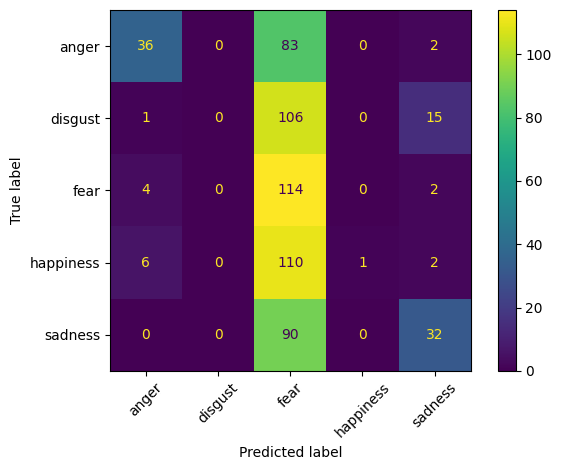

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = sorted(results["true_emotion"].unique())

cm = confusion_matrix(
    results["true_emotion"],
    results["predicted_emotion"],
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(xticks_rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
print(results["predicted_emotion"].value_counts())

predicted_emotion
fear         503
sadness       53
anger         47
happiness      1
Name: count, dtype: int64
